# 🤖 Naive Bayes Classifier — Detailed Study Notes

Naive Bayes is a **supervised machine learning algorithm** based on **Bayes' Theorem** and the assumption of **feature independence** (hence the term "naive"). It is widely used for **classification tasks**, especially **text classification**, **spam filtering**, and **sentiment analysis**.

---

## 🧠 What Does "Naive" and "Bayes" Mean?

### ✅ "Naive"
- Assumes that **all features (input variables)** used in the model are **independent of each other**.
- This is often **not true** in real-world data, but the model still performs surprisingly well.

### ✅ "Bayes"
- Refers to **Bayes' Theorem**, which is a method for **calculating conditional probability**.

---

## 📐 Bayes' Theorem

Bayes' Theorem is a **mathematical formula** used to determine the **probability of an event based on prior knowledge** of conditions that might be related to the event.

### 🔸 Formula:
\[
P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}
\]

### 🔸 Terms:
- **P(A|B)** → Posterior: Probability of A given B (what we want to find)
- **P(B|A)** → Likelihood: Probability of B given A
- **P(A)** → Prior: Probability of A before seeing B
- **P(B)** → Marginal: Total probability of B across all classes

---

## 🎲 Probability Basics Refresher

### ✅ Probability of an Event:
\[
P(E) = \frac{\text{Favorable outcomes}}{\text{Total outcomes}}
\]

- Always between 0 and 1:  
  \[
  0 \leq P(E) \leq 1
  \]

### ✅ Independent Probability:
- Two events are independent if:
  \[
  P(A \cap B) = P(A) \cdot P(B)
  \]
- The outcome of one does **not affect** the other.

### ✅ Dependent Probability:
- Two events are dependent if:
  \[
  P(A \cap B) \neq P(A) \cdot P(B)
  \]
- One event’s outcome **influences** the probability of the other.

---

## 🔍 What is Naive Bayes?

Naive Bayes is a **probabilistic classification algorithm** that:
- Uses **Bayes' Theorem**
- Assumes that all features are **independent**
- Calculates the **posterior probability** for each class and chooses the class with the **highest probability**

---

## 📦 When to Use Naive Bayes?

Naive Bayes is best used when:
- You need a **fast and simple classifier**
- You have **high-dimensional data** (many features)
- The input features are **categorical, text, or boolean**
- You're working with **text classification** tasks like:
  - Email spam detection
  - Sentiment analysis
  - Document categorization

---

## 🧪 Types of Naive Bayes Classifiers

There are **three major types** based on the nature of input data:

---

### 1️⃣ Gaussian Naive Bayes

- Assumes that features follow a **normal (Gaussian) distribution**
- Used when input features are **continuous**
- Example use case: **Iris dataset**, where petal length and width are continuous values

**Formula for Gaussian likelihood:**
\[
P(x_i | y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \cdot e^{-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}}
\]

---

### 2️⃣ Multinomial Naive Bayes

- Used for **discrete features** such as **word counts or frequencies**
- Often used in **text classification**, such as spam filtering or news categorization
- Works with **term frequency vectors** or **TF-IDF**

**Example:**  
Classifying a tweet or document into categories like sports, politics, or entertainment.

---

### 3️⃣ Bernoulli Naive Bayes

- Used for **binary/boolean features** (e.g., 0 or 1, yes/no, true/false)
- Assumes features are generated from a **Bernoulli distribution**
- Also used in **text classification**, especially with **binary word occurrence vectors** (e.g., "is the word 'offer' present or not?")

---

## 📌 Summary Table

| Type         | Input Feature Type        | Assumes           | Use Case Example              |
|--------------|---------------------------|-------------------|-------------------------------|
| Gaussian     | Continuous (real numbers) | Normal distribution | Iris flower classification   |
| Multinomial  | Discrete/count-based      | Word frequencies   | Spam detection, news classification |
| Bernoulli    | Binary (0/1, True/False)  | Binary occurrence  | Text classification (with binary vectors) |

---

## 🧾 Final Takeaway

- Naive Bayes is **simple**, **fast**, and **powerful** for many real-world classification problems.
- Despite its **"naive" independence assumption**, it performs well in practice.
- Choose the **right variant** (Gaussian, Multinomial, Bernoulli) based on the **data type**.



> ✅ Tip: Always evaluate Naive Bayes using **confusion matrix**, **precision**, **recall**, and **F1-score**, especially when working with imbalanced datasets.

----


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from mlxtend.plotting import plot_decision_regions

In [5]:
dataset = pd.read_csv(r"C:\Users\junai\Desktop\coding\ML\student_placement_data.csv")
dataset.head()

,cgpa,score,placed
0,6.87,7.79,1
1,9.75,7.14,1
2,8.66,6.24,1
3,7.99,8.26,1
4,5.78,7.74,1


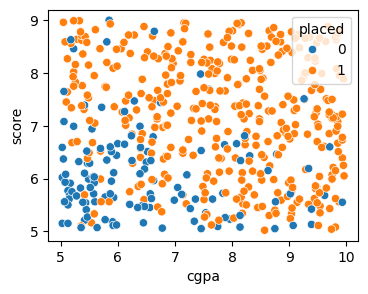

In [7]:
# chekc for linearly or non linearly seperable

plt.figure(figsize=(4,3))
sns.scatterplot(x="cgpa", y="score",data=dataset,hue="placed")
plt.show()

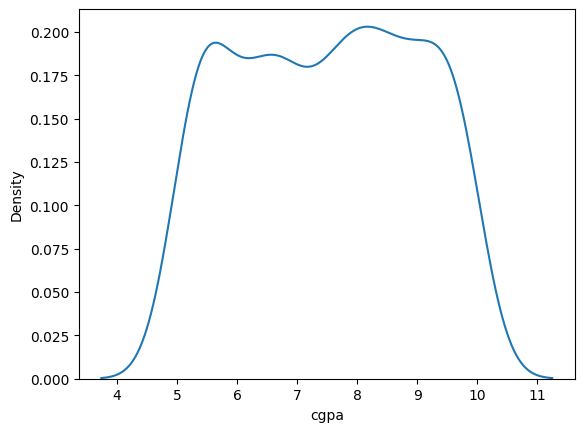

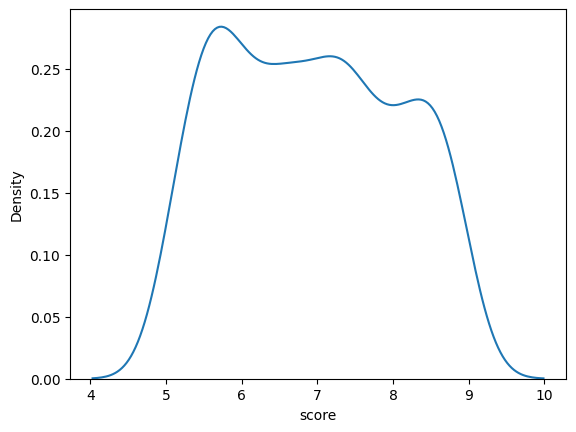

In [11]:
# wee can see that data is almost linearly seperable
# but ther is also a bit misclassification

# now lets check for nomral distribution
sns.kdeplot(data=dataset["cgpa"])
plt.show()

sns.kdeplot(data=dataset["score"])
plt.show()

In [12]:
# we can see that data is almost in  normal distribution

# depenednt / indepepdnet 
x = dataset.iloc[: , :-1]
y = dataset["placed"]

from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x , y , random_state=42 , test_size=0.2)

In [ ]:
# gaussian NB must be applied due to data nature 
# but however let us now aplly all 3 type of naive bayes

from sklearn.naive_bayes import GaussianNB ,MultinomialNB , BernoulliNB

In [15]:
gnb = GaussianNB()
gnb.fit(x_train,y_train)

GaussianNB()

In [17]:
gnb.score(x_test,y_test)*100

88.0

In [18]:
mnb = MultinomialNB()
mnb.fit(x_train,y_train)

MultinomialNB()

In [20]:
mnb.score(x_test,y_test)*100

78.0

In [21]:
bnb = BernoulliNB()
bnb.fit(x_train,y_train)

BernoulliNB()

In [22]:
bnb.score(x_test,y_test)*100

78.0

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


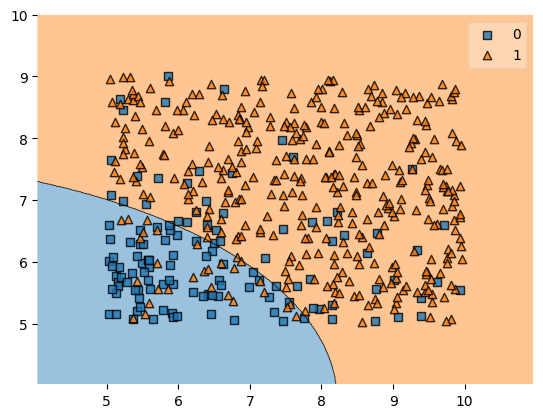

In [23]:
# we can that gaussian give the max accuracy

# now chekc the decision region of each graph

plot_decision_regions(x.to_numpy(),y.to_numpy(), clf= gnb)
plt.show()

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(


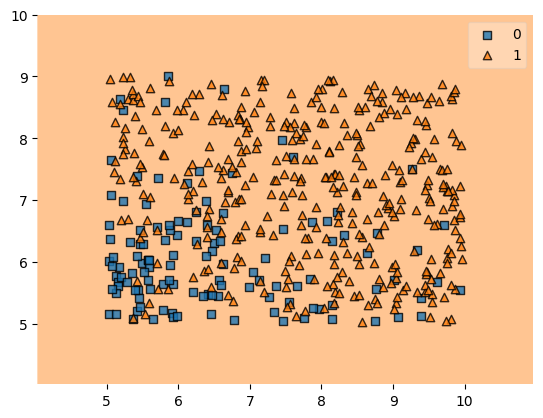

In [24]:
plot_decision_regions(x.to_numpy(),y.to_numpy(), clf= mnb)
plt.show()

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but BernoulliNB was fitted with feature names
  warnings.warn(


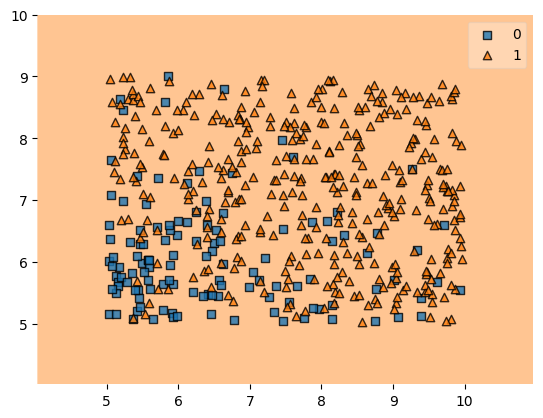

In [25]:
plot_decision_regions(x.to_numpy(),y.to_numpy(), clf= bnb)
plt.show()

In [26]:
# thus we can clearly see  that only GNB was able to classify data into proper regions